In [1]:
!pip install -q -U transformers accelerate

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import re
import json
import glob
import time
import subprocess
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoProcessor, LlavaForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
device: cuda


In [2]:
MODEL_NAME = "llava-hf/llava-1.5-7b-hf"
DT = torch.float16

processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = LlavaForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=DT,
    device_map="auto",
    max_memory={0: "12GiB", 1: "12GiB"},
    attn_implementation="sdpa",
)
model.eval()
for p_ in model.parameters():
    p_.requires_grad_(False)

lm = model.model.language_model
lm_head = model.lm_head
layers = lm.layers
n_layer = model.config.text_config.num_hidden_layers
n_head = model.config.text_config.num_attention_heads
hidden_dim = model.config.text_config.hidden_size
head_dim = hidden_dim // n_head
IMAGE_TOKEN_ID = getattr(model.config, "image_token_id", None) or model.config.image_token_index
assert len(layers) == n_layer
assert model.config.text_config._attn_implementation == "sdpa"
print(n_layer, "language model layers,", n_head, "heads,", head_dim, "head dim, image token id", IMAGE_TOKEN_ID)

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

32 language model layers, 32 heads, 128 head dim, image token id 32000


In [3]:
INPUT = "/kaggle/input/datasets/nocturnalnerd18"
USERNAME = "nocturnalnerd18"
AMBER_IMAGE_DIR = "/kaggle/input/datasets/nocturnalnerd18/amber-hallucination/image"

N_UNITS = 100
DRIVEN_TE = -1.0
SLUG = f"{USERNAME}/patch-llava-circuit-dissect"
N_ADD = 8
MAX_HOURS = 9.0
PILOT_UNITS = 2
BATCH_SAVE_SIZE = 20
UPLOAD_EVERY = 2
CHECK_TOL = 0.25
YES_ID, NO_ID = 3869, 1939
TAIL_N = 4
GROUPS = ["visual", "text", "tail"]
OUT_DIR = "/kaggle/working/patch_llava_circuit_dissect"
os.makedirs(OUT_DIR, exist_ok=True)

ROUTERS = [("mlp", 10, -1, "visual"), ("head", 11, 26, "text"), ("head", 12, 13, "text")]
FIXED_CORE = ROUTERS + [("head", 16, 15, "all"), ("head", 16, 0, "all")]
FALLBACK_SURVIVORS = [("mlp", 16, -1, "all"), ("mlp", 17, -1, "all"), ("mlp", 18, -1, "all"), ("mlp", 28, -1, "all"), ("mlp", 31, -1, "all")]


def load_image(path):
    return Image.open(path).convert("RGB")


def build_inputs(image, text):
    conversation = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt_text = processor.apply_chat_template(conversation, add_generation_prompt=True)
    return processor(text=prompt_text, images=image, return_tensors="pt").to(model.device, DT)


def resolve_image_path(q):
    if q["question_id"].startswith("amber_"):
        return os.path.join(AMBER_IMAGE_DIR, f"{q['image_id']}.jpg")
    return None


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


with open(f"{INPUT}/vlm-questions/all_questions.json") as f:
    all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2"
question_by_id = {q["question_id"]: q for q in all_questions}
assert [processor.tokenizer.decode([i]).strip() for i in (YES_ID, NO_ID)] == ["Yes", "No"]

atp = {}
atp_files = sorted(glob.glob(f"{INPUT}/atp-llava-noising/**/*_batch_*.pt", recursive=True), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p)))
for path in atp_files:
    for e in torch.load(path):
        if e["ok"]:
            atp[e["question_id"]] = {k: e[k] for k in (
                "question_id", "image_id", "hallucination_type", "stratum", "group", "source", "split", "sign", "seed",
                "delta_clean", "delta_corrupt", "TE", "noise_used", "head", "mlp",
            )}
print(f"atp-llava-noising: {len(atp_files)} batch files, {len(atp)} ok entries")
assert len(atp) >= 0.98 * 8403, "attach atp-llava-noising (all batches)"

meta = pd.DataFrame([{k: v for k, v in a.items() if k not in ("head", "mlp")} for a in atp.values()])
meta["gap_clean"] = meta.sign * meta.delta_clean
fy_all = meta[(meta.stratum == "false_yes") & (meta.hallucination_type == "attribute") & (meta.TE < DRIVEN_TE)]
ty_all = meta[(meta.stratum == "true_yes") & (meta.hallucination_type == "attribute")]
rng = np.random.default_rng(0)
units = []
for (s, sp), g in fy_all.groupby(["source", "split"]):
    pool = ty_all[(ty_all.source == s) & (ty_all.split == sp)].set_index("question_id").gap_clean
    ids = g.question_id.tolist()
    gaps = g.set_index("question_id").gap_clean
    for rank, i in enumerate(rng.permutation(len(ids))):
        qid = ids[i]
        ctrl = None
        if len(pool):
            ctrl = (pool - gaps[qid]).abs().idxmin()
            pool = pool.drop(ctrl)
        units.append({"fy": qid, "ctrl": ctrl, "key": (rank + 0.5) / len(ids), "stratum": f"{s}/{sp}"})
units.sort(key=lambda u: (u["key"], u["stratum"]))
for i, u in enumerate(units):
    u["uid"] = i
print(len(units), "driven attribute false_yes units,", sum(u["ctrl"] is not None for u in units), "with a matched true_yes control")
stage_units = units[:N_UNITS]
uid_of = {}
for u in stage_units:
    uid_of[u["fy"]] = u["uid"]
    if u["ctrl"] is not None:
        uid_of[u["ctrl"]] = u["uid"]
stage_ids = list(uid_of)
print(f"{len(stage_units)} units, {len(stage_ids)} questions")
print(pd.Series([u["stratum"] for u in stage_units]).value_counts().to_string())


def comp_name(kind, layer, head, group):
    base = f"L{layer} H{head}" if kind == "head" else f"L{layer} MLP"
    return f"{base} {group}"


CORE = {}
for c in FIXED_CORE:
    CORE[comp_name(*c)] = c
survivors_path = f"{INPUT}/patch-llava-effects/survivors.json"
if os.path.exists(survivors_path):
    with open(survivors_path) as f:
        survivors = json.load(f)
    for s in survivors.values():
        c = s["cell"]
        CORE[comp_name(c["kind"], c["layer"], c["head"], c["group"])] = (c["kind"], c["layer"], c["head"], c["group"])
    print(len(survivors), "survivors read from patch-llava-effects")
else:
    print("patch-llava-effects not attached, using the fallback survivors")
    for c in FALLBACK_SURVIVORS:
        CORE[comp_name(*c)] = c
CORE_COMPS = list(CORE.values())
print(len(CORE_COMPS), "core circuit components:", list(CORE))

train_fy = [q for q in fy_all[fy_all.split == "train"].question_id if q in atp]
sup_head = np.zeros((len(GROUPS), n_layer, n_head))
sup_mlp = np.zeros((len(GROUPS), n_layer))
for q in train_fy:
    a = atp[q]
    sup_head += (-a["sign"] * a["head"]).numpy()
    sup_mlp += (-a["sign"] * a["mlp"]).numpy()
sup_head /= len(train_fy)
sup_mlp /= len(train_fy)
print(f"signed attribution patching support for Yes on {len(train_fy)} driven train false_yes questions")


def comp_support(c):
    kind, layer, head, group = c
    arr = sup_head[:, layer, head] if kind == "head" else sup_mlp[:, layer]
    return float(arr.sum() if group == "all" else arr[GROUPS.index(group)])


PROMOTERS = [c for c in CORE_COMPS if comp_support(c) > 0]
BRAKES = [c for c in CORE_COMPS if comp_support(c) <= 0]
print("core promoters (positive support):", [(comp_name(*c), round(comp_support(c), 3)) for c in PROMOTERS])
print("core brakes (non-positive support):", [(comp_name(*c), round(comp_support(c), 3)) for c in BRAKES])
core_all = {(k, l, h) for k, l, h, g in CORE_COMPS if g == "all"}
cands = [("head", l, h, "all") for l in range(n_layer) for h in range(n_head)] + [("mlp", l, -1, "all") for l in range(n_layer)]
cands = [c for c in cands if (c[0], c[1], c[2]) not in core_all]
RANKED_POS = [c for c in sorted(cands, key=lambda c: -comp_support(c)) if comp_support(c) > 0]
print("top positive additions:", [(comp_name(*c), round(comp_support(c), 3)) for c in RANKED_POS[:N_ADD]])


def cell_name(entries):
    kind, layer, head = entries[0][0], entries[0][1], entries[0][2]
    groups = {e[3] for e in entries}
    base = f"L{layer} H{head}" if kind == "head" else f"L{layer} MLP"
    return base if len(groups) > 1 or "all" in groups else f"{base}[{next(iter(groups))}]"


core_entries, add_entries = {}, {}
for c in CORE_COMPS:
    core_entries.setdefault(c[:3], []).append(c)
for c in RANKED_POS[:N_ADD]:
    add_entries.setdefault(c[:3], []).append(c)
P_KEYS = [k_ for k_, es in core_entries.items() if any(e in PROMOTERS for e in es)]
B_KEYS = [k_ for k_, es in core_entries.items() if k_ not in P_KEYS]
A_KEYS = [k_ for k_ in add_entries if k_ not in core_entries]
PA_KEYS = P_KEYS + A_KEYS
members = {}
for k_ in P_KEYS:
    members[k_] = core_entries[k_] + add_entries.get(k_, [])
for k_ in A_KEYS:
    members[k_] = add_entries[k_]
for k_ in B_KEYS:
    members[k_] = core_entries[k_]
NAME = {k_: cell_name(members[k_]) for k_ in members}
ROLE = {k_: "promoter" if k_ in P_KEYS else "brake" if k_ in B_KEYS else "addition" for k_ in members}
print("promoter cells:", [NAME[k_] for k_ in P_KEYS])
print("brake cells:", [NAME[k_] for k_ in B_KEYS])
print("addition cells:", [NAME[k_] for k_ in A_KEYS])


def comps_of(keys, skip=None):
    return [e for k_ in keys if k_ != skip for e in members[k_]]


STEP_COMPS = {"P": [e for k_ in P_KEYS for e in core_entries[k_]], "B": [e for k_ in B_KEYS for e in core_entries[k_]], "PA": comps_of(PA_KEYS)}
for k_ in P_KEYS + B_KEYS:
    STEP_COMPS[f"single:{NAME[k_]}"] = list(core_entries[k_])
for k_ in A_KEYS:
    STEP_COMPS[f"single:{NAME[k_]}"] = list(add_entries[k_])
for k_ in PA_KEYS:
    STEP_COMPS[f"loo_PA:{NAME[k_]}"] = comps_of(PA_KEYS, skip=k_)
for k_ in B_KEYS:
    STEP_COMPS[f"loo_B:{NAME[k_]}"] = comps_of(B_KEYS, skip=k_)
STEP_NAMES = list(STEP_COMPS)
print(len(STEP_NAMES), "steps,", 2 * len(STEP_NAMES), "forwards per question")


def prep(qid):
    q = question_by_id[qid]
    inputs = build_inputs(load_image(resolve_image_path(q)), q["question_text"])
    ids = inputs["input_ids"]
    T = ids.shape[1]
    vis = ids[0] == IMAGE_TOKEN_ID
    tail = torch.zeros(T, dtype=torch.bool, device=ids.device)
    tail[-TAIL_N:] = True
    text = ~vis & ~tail
    assert int(vis.sum()) == 576 and not bool((vis & tail).any())
    return {
        "qid": qid, "T": T, "input_ids": ids, "pixel_values": inputs["pixel_values"],
        "attention_mask": inputs["attention_mask"], "vis": vis,
        "idx": {
            "all": torch.arange(T), "visual": torch.nonzero(vis.cpu())[:, 0],
            "text": torch.nonzero(text.cpu())[:, 0], "tail": torch.nonzero(tail.cpu())[:, 0],
        },
        "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0,
    }


def image_ok(qid):
    path = resolve_image_path(question_by_id[qid])
    return path is not None and os.path.exists(path)

atp-llava-noising: 43 batch files, 8403 ok entries
777 driven attribute false_yes units, 777 with a matched true_yes control
100 units, 200 questions
amber/train    72
amber/val      14
amber/test     14
11 survivors read from patch-llava-effects
15 core circuit components: ['L10 MLP visual', 'L11 H26 text', 'L12 H13 text', 'L16 H15 all', 'L16 H0 all', 'L16 MLP all', 'L16 MLP tail', 'L16 H15 tail', 'L17 MLP all', 'L17 MLP tail', 'L28 MLP all', 'L28 MLP tail', 'L31 MLP all', 'L18 MLP tail', 'L18 MLP all']
signed attribution patching support for Yes on 558 driven train false_yes questions
core promoters (positive support): [('L11 H26 text', 0.571), ('L16 MLP all', 0.218), ('L16 MLP tail', 0.179), ('L17 MLP all', 1.04), ('L17 MLP tail', 1.005), ('L18 MLP tail', 0.277), ('L18 MLP all', 0.305)]
core brakes (non-positive support): [('L10 MLP visual', -0.277), ('L12 H13 text', -0.505), ('L16 H15 all', -0.166), ('L16 H0 all', -0.217), ('L16 H15 tail', -0.168), ('L28 MLP all', -0.933), ('L28 ML

In [4]:
STATE = {"noise": None, "seed": 0, "capture": False, "live": None, "vis": None, "freeze": None}


def _layer_pre(l):
    def hook(module, args, kwargs):
        if l != 0 or STATE["noise"] is None:
            return None
        h = args[0] if args else kwargs["hidden_states"]
        vis = STATE["vis"]
        h = h.clone()
        x = h[:, vis].float()
        generator = torch.Generator().manual_seed(STATE["seed"])
        noise = torch.randn(x.shape, generator=generator).to(h.device)
        h[:, vis] = (x + noise * x.std() * STATE["noise"]).to(h.dtype)
        if args:
            return (h,) + tuple(args[1:]), kwargs
        kwargs = dict(kwargs)
        kwargs["hidden_states"] = h
        return args, kwargs
    return hook


def _z_pre(l):
    def hook(module, args):
        z = args[0]
        fz = STATE["freeze"]
        if fz is not None:
            m = fz["z"][l]
            if m is None:
                return None
            B, T = z.shape[0], z.shape[1]
            src = fz["src"]["z"][l][0].view(T, n_head, head_dim).to(z.device, z.dtype)
            z4 = torch.where(m.to(z.device)[None, :, :, None], src[None], z.view(B, T, n_head, head_dim))
            return (z4.view(B, T, n_head * head_dim),) + tuple(args[1:])
        if STATE["capture"]:
            STATE["live"]["z"][l] = z
        return None
    return hook


def _mlp_fwd(l):
    def hook(module, args, output):
        fz = STATE["freeze"]
        if fz is not None:
            m = fz["m"][l]
            if m is None:
                return None
            src = fz["src"]["mlp"][l][0].to(output.device, output.dtype)
            return torch.where(m.to(output.device)[None, :, None], src[None], output)
        if STATE["capture"]:
            STATE["live"]["mlp"][l] = output
        return None
    return hook


_handles = []
for l, layer in enumerate(layers):
    _handles.append(layer.register_forward_pre_hook(_layer_pre(l), with_kwargs=True))
    _handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_z_pre(l)))
    _handles.append(layer.mlp.register_forward_hook(_mlp_fwd(l)))
print(len(_handles), "hooks registered")

96 hooks registered


In [5]:
@torch.no_grad()
def run_forward(p, noise, seed, freeze=None, capture=False):
    STATE.update(noise=noise, seed=seed, capture=capture, freeze=freeze, vis=p["vis"])
    if capture:
        STATE["live"] = {"z": [None] * n_layer, "mlp": [None] * n_layer}
    out = model(input_ids=p["input_ids"], pixel_values=p["pixel_values"], attention_mask=p["attention_mask"], use_cache=False, logits_to_keep=1)
    logits = out.logits[0, -1].float()
    delta = float(p["sign"] * (logits[YES_ID] - logits[NO_ID]))
    result = {"acts": STATE["live"], "delta": delta} if capture else delta
    STATE.update(noise=None, capture=False, freeze=None, live=None)
    del out, logits
    return result


def build_mask(p, comps):
    T = p["T"]
    hm = torch.zeros(n_layer, T, n_head, dtype=torch.bool)
    mm = torch.zeros(n_layer, T, dtype=torch.bool)
    for kind, layer, head, group in comps:
        idx = p["idx"][group]
        if kind == "head":
            hm[layer, idx, head] = True
        else:
            mm[layer, idx] = True
    return hm, mm


def make_freeze(hm, mm, src, invert):
    zs, ms = [], []
    for l in range(n_layer):
        a, b = hm[l], mm[l]
        if invert:
            a, b = ~a, ~b
        zs.append(a if bool(a.any()) else None)
        ms.append(b if bool(b.any()) else None)
    return {"z": zs, "m": ms, "src": src["acts"]}


def two_configs(p, clean, corrupt, comps, seed, noise):
    hm, mm = build_mask(p, comps)
    knock = run_forward(p, None, seed, make_freeze(hm, mm, corrupt, False))
    restore = run_forward(p, noise, seed, make_freeze(hm, mm, clean, False))
    return [knock, restore]


CONFIG_NAMES = ["knockout", "restored"]


def circuit_curve(p, clean, corrupt, seed, noise):
    return np.array([two_configs(p, clean, corrupt, STEP_COMPS[n], seed, noise) for n in STEP_NAMES], dtype=np.float32)


ALL_COMPS = [("head", l, h, "all") for l in range(n_layer) for h in range(n_head)] + [("mlp", l, -1, "all") for l in range(n_layer)]

In [6]:
pilot_ids = [q for u in stage_units for q in (u["fy"], u["ctrl"]) if q is not None and image_ok(q)][:2 * PILOT_UNITS]
secs, base_err, id_err, plain_err = [], [], [], []
for qid in pilot_ids:
    a = atp[qid]
    p = prep(qid)
    t0 = time.time()
    clean = run_forward(p, None, a["seed"], capture=True)
    corrupt = run_forward(p, a["noise_used"], a["seed"], capture=True)
    base_err.append(max(abs(clean["delta"] - a["delta_clean"]), abs(corrupt["delta"] - a["delta_corrupt"])))
    plain_err.append(max(abs(run_forward(p, None, a["seed"]) - clean["delta"]), abs(run_forward(p, a["noise_used"], a["seed"]) - corrupt["delta"])))
    t_cap = time.time() - t0
    all_knock, all_restore = two_configs(p, clean, corrupt, ALL_COMPS, a["seed"], a["noise_used"])
    none_knock, none_restore = two_configs(p, clean, corrupt, [], a["seed"], a["noise_used"])
    id_err.append(max(abs(all_knock - corrupt["delta"]), abs(all_restore - clean["delta"]), abs(none_knock - clean["delta"]), abs(none_restore - corrupt["delta"])))
    t1 = time.time()
    curve = circuit_curve(p, clean, corrupt, a["seed"], a["noise_used"])
    secs.append(t_cap + time.time() - t1)
    print(f"{qid} {a['stratum']:9s} T={p['T']}: {secs[-1]:.1f} s for {len(STEP_NAMES)} steps | clean {clean['delta']:+.2f} (atp run {a['delta_clean']:+.2f}) corrupt {corrupt['delta']:+.2f} ({a['delta_corrupt']:+.2f})")
    print(pd.DataFrame(curve, index=STEP_NAMES, columns=CONFIG_NAMES).round(2).head(12).to_string())
    del p, clean, corrupt
    torch.cuda.empty_cache()
print(f"clean and corrupt deltas vs the attribution patching run: max abs diff {max(base_err):.3f}")
print(f"capture runs vs plain runs: max abs diff {max(plain_err):.3f}")
print(f"identity checks (freezing every component, or none, must give the other run or the same run): max abs error {max(id_err):.3f}")
print(f"pilot speed: {np.mean(secs):.1f} s per question, projected {np.mean(secs) * len(stage_ids) / 3600:.1f} h for {len(stage_ids)} questions")
assert max(base_err) < CHECK_TOL, "clean or corrupt deltas differ from the attribution patching collection"
assert max(plain_err) < CHECK_TOL, "capture runs differ from plain runs"
assert max(id_err) < CHECK_TOL, "freezing every component does not reproduce the other run"

amber_6446 false_yes T=598: 35.9 s for 37 steps | clean -0.62 (atp run -0.62) corrupt +0.41 (+0.41)
                        knockout  restored
P                          -0.08     -0.20
B                          -2.38      2.20
PA                          0.98     -0.44
single:L11 H26             -0.44      0.38
single:L16 MLP             -0.39     -0.23
single:L17 MLP             -0.17     -0.32
single:L18 MLP             -0.64      0.43
single:L10 MLP[visual]     -0.47      0.43
single:L12 H13[text]       -0.91      0.44
single:L16 H15             -0.89      0.59
single:L16 H0              -0.98      0.89
single:L28 MLP             -1.12      0.72
amber_4883 true_yes  T=596: 36.6 s for 37 steps | clean +0.62 (atp run +0.62) corrupt +0.97 (+0.97)
                        knockout  restored
P                           0.69     -0.23
B                           3.13     -1.86
PA                          0.05      0.94
single:L11 H26              0.12      0.84
single:L16 MLP            

In [7]:
def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    cleaned = "\n".join(l for l in out.splitlines() if "upload info" not in l.lower()).lower()
    bad = ("client error", "forbidden", "unauthorized", "traceback", "error:", "failed")
    return r.returncode == 0 and not any(x in cleaned for x in bad), out


ok, out = _run(["kaggle", "datasets", "download", "-d", SLUG, "-p", OUT_DIR, "--unzip"])
if ok:
    print("restored", len(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt"))), "batch files from", SLUG)
else:
    if not any(s in out.lower() for s in ("404", "403", "not found", "does not exist", "forbidden")):
        raise RuntimeError("download failed for an unrelated reason, refusing to start fresh:\n" + out)
    print("no existing dataset, starting fresh")
dataset_exists = ok

with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({
        "title": SLUG.split("/")[1],
        "id": SLUG,
        "subtitle": "Per-cell dissection of LLaVA promoter and brake sets",
        "description": "Per-cell dissection on LLaVA-1.5-7B of the promoter and brake sets for driven attribute false_yes questions (TE below -1) and matched true_yes controls from atp-llava-noising. "
                       "curve has shape [step, 2] holding the sign-corrected Yes minus No logit gap at the last position for knockout (clean input, the set takes its corrupt activations) and restored (corrupt input, the set takes its clean activations). "
                       "Steps are the promoter set P, the brake set B, the promoters plus the top positive additions PA, every cell alone (single), and each cell left out of PA or B (loo). Names are in circuit_meta.json.",
        "licenses": [{"name": "CC0-1.0"}],
    }, f)


def upload(msg):
    global dataset_exists
    version_cmd = ["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", msg]
    create_cmd = ["kaggle", "datasets", "create", "-p", OUT_DIR]
    ok_, out_ = _run(version_cmd if dataset_exists else create_cmd)
    if not ok_ and not dataset_exists:
        time.sleep(30)
        ok_, out2 = _run(version_cmd)
        out_ += "\n--- version retry ---\n" + out2
    if ok_:
        dataset_exists = True
        print(f"    [upload ok] {msg}")
    else:
        cleaned = [l for l in out_.splitlines() if l.strip() and "upload info" not in l.lower() and "B/s]" not in l and "it/s]" not in l]
        print(f"    [UPLOAD FAILED, continuing] account {USERNAME}, dataset {SLUG}\n" + "\n".join(cleaned[-8:]))
    return ok_


with open(os.path.join(OUT_DIR, "circuit_meta.json"), "w") as f:
    json.dump({
        "step_names": STEP_NAMES, "config_names": CONFIG_NAMES, "steps": {n: [list(c) for c in STEP_COMPS[n]] for n in STEP_NAMES},
        "cells": {NAME[k_]: {"role": ROLE[k_], "members": [list(c) for c in members[k_]]} for k_ in members},
        "p_cells": [NAME[k_] for k_ in P_KEYS], "b_cells": [NAME[k_] for k_ in B_KEYS], "a_cells": [NAME[k_] for k_ in A_KEYS],
        "n_units": N_UNITS, "tail_n": TAIL_N, "yes_id": YES_ID, "no_id": NO_ID,
    }, f)


def collect():
    paths = sorted(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt")), key=batch_number)
    done_ids = set()
    for path in paths:
        done_ids.update(e["question_id"] for e in torch.load(path))
    todo = [q for q in stage_ids if q not in done_ids]
    print(f"{len(stage_ids)} questions, {len(done_ids)} already done, {len(todo)} to run")
    batch_entries, batch_index, failed, missing = [], len(paths), 0, 0
    t_start = time.time()
    stopped = False
    for i, qid in enumerate(todo):
        if not image_ok(qid):
            missing += 1
            continue
        a = atp[qid]
        q = question_by_id[qid]
        entry = {
            "question_id": qid, "uid": uid_of[qid], "image_id": q["image_id"], "stratum": a["stratum"], "source": a["source"], "split": a["split"],
            "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0, "atp_delta_clean": a["delta_clean"], "atp_delta_corrupt": a["delta_corrupt"],
        }
        try:
            p = prep(qid)
            clean = run_forward(p, None, a["seed"], capture=True)
            corrupt = run_forward(p, a["noise_used"], a["seed"], capture=True)
            curve = circuit_curve(p, clean, corrupt, a["seed"], a["noise_used"])
            entry.update(ok=True, T=p["T"], delta_clean=clean["delta"], delta_corrupt=corrupt["delta"], curve=torch.from_numpy(curve))
            del p, clean, corrupt
        except torch.cuda.OutOfMemoryError:
            STATE.update(capture=False, live=None, noise=None, freeze=None)
            torch.cuda.empty_cache()
            entry.update(ok=False, reason="oom")
            failed += 1
        batch_entries.append(entry)
        if len(batch_entries) >= BATCH_SAVE_SIZE:
            torch.save(batch_entries, os.path.join(OUT_DIR, f"C_batch_{batch_index}.pt"))
            batch_entries, batch_index = [], batch_index + 1
            if batch_index % UPLOAD_EVERY == 0:
                upload(f"{batch_index} batches")
        if i % 10 == 0 and i > 0:
            torch.cuda.empty_cache()
            avg = (time.time() - t_start) / (i + 1)
            print(f"[{i + 1}/{len(todo)}] {qid} ({avg:.1f} s/question avg, ETA {avg * (len(todo) - i - 1) / 3600:.1f} h, failed {failed}, missing images {missing})")
        if time.time() - t_start > MAX_HOURS * 3600:
            stopped = True
            print(f"time budget of {MAX_HOURS} h reached after {i + 1} questions; re-run this notebook to resume")
            break
    if batch_entries:
        torch.save(batch_entries, os.path.join(OUT_DIR, f"C_batch_{batch_index}.pt"))
    upload("paused" if stopped else "done")
    print(f"done, failed {failed}, missing images {missing}, {(time.time() - t_start) / 3600:.2f} h, complete {not stopped}")


collect()

no existing dataset, starting fresh
200 questions, 0 already done, 200 to run
[11/200] amber_2454 (38.6 s/question avg, ETA 2.0 h, failed 0, missing images 0)
[21/200] amber_3018 (38.6 s/question avg, ETA 1.9 h, failed 0, missing images 0)
[31/200] amber_4380 (38.6 s/question avg, ETA 1.8 h, failed 0, missing images 0)
    [upload ok] 2 batches
[41/200] amber_8300 (38.8 s/question avg, ETA 1.7 h, failed 0, missing images 0)
[51/200] amber_6150 (38.7 s/question avg, ETA 1.6 h, failed 0, missing images 0)
[61/200] amber_2614 (38.7 s/question avg, ETA 1.5 h, failed 0, missing images 0)
[71/200] amber_3514 (38.7 s/question avg, ETA 1.4 h, failed 0, missing images 0)
    [upload ok] 4 batches
[81/200] amber_3186 (38.7 s/question avg, ETA 1.3 h, failed 0, missing images 0)
[91/200] amber_4034 (38.7 s/question avg, ETA 1.2 h, failed 0, missing images 0)
[101/200] amber_4122 (38.7 s/question avg, ETA 1.1 h, failed 0, missing images 0)
[111/200] amber_3540 (38.7 s/question avg, ETA 1.0 h, faile

200 entries, 200 ok, 0 stage questions not done
0 questions with a non-finite value are excluded
--- sets: shares over 100 driven false_yes questions and specificity over 100 units ---
    cells              knockout              restored            spec knockout            spec restored
P       4  +0.64 [+0.61, +0.67]  +0.54 [+0.50, +0.58]  +0.371 [+0.252, +0.487]  +0.240 [+0.104, +0.379]
B       6  -0.80 [-0.94, -0.70]  -0.57 [-0.69, -0.48]  -0.728 [-0.942, -0.523]  -0.769 [-0.983, -0.557]
PA     11  +1.18 [+1.14, +1.23]  +0.95 [+0.92, +0.99]  +0.211 [+0.090, +0.338]  +0.301 [+0.132, +0.472]
--- each cell alone ---
           cell     role             knockout             restored           spec knockout           spec restored
        L11 H26 promoter +0.30 [+0.26, +0.33] +0.01 [+0.00, +0.02] +0.273 [+0.167, +0.370] +0.012 [-0.014, +0.038]
        L16 MLP promoter +0.17 [+0.14, +0.20] +0.37 [+0.34, +0.40] +0.266 [+0.180, +0.356] +0.228 [+0.147, +0.315]
        L17 MLP promoter +0.46

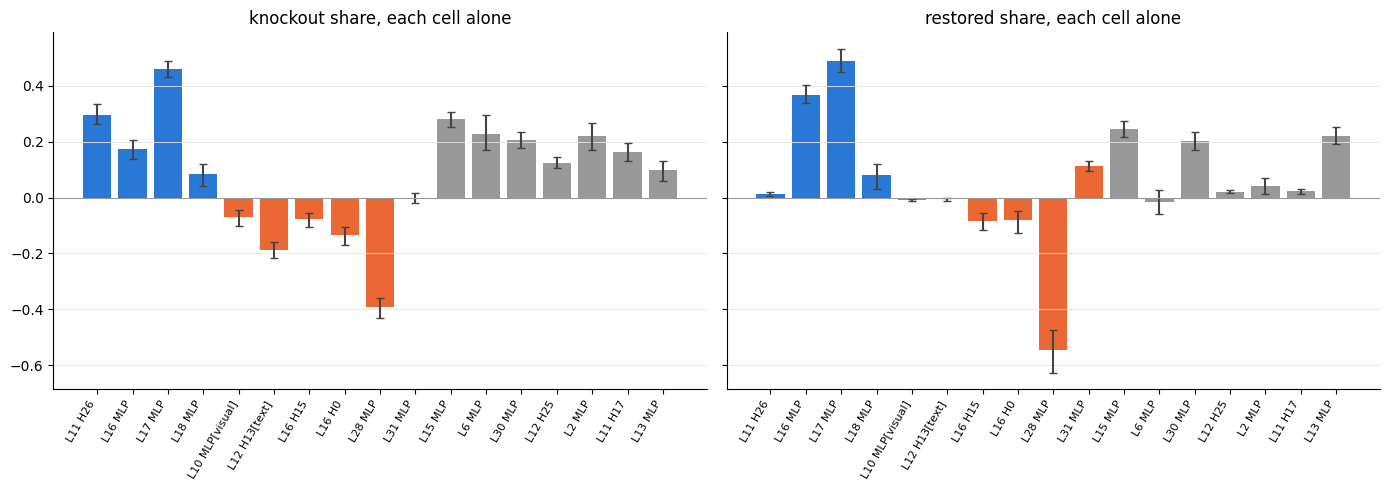

    [upload ok] summary


In [8]:
entries = []
for path in sorted(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt")), key=batch_number):
    entries.extend(torch.load(path))
good = [e for e in entries if e["ok"]]
assert len({e["question_id"] for e in good}) == len(good), "duplicated entries"
print(f"{len(entries)} entries, {len(good)} ok, {len(stage_ids) - len(good)} stage questions not done")
finite = [bool(np.isfinite(e["curve"].numpy()).all()) for e in good]
print(f"{len(good) - sum(finite)} questions with a non-finite value are excluded")
good = [e for e, ok_ in zip(good, finite) if ok_]

CV = np.stack([e["curve"].numpy() for e in good]).astype(np.float64)
dc = np.array([e["delta_clean"] for e in good])
dk = np.array([e["delta_corrupt"] for e in good])
sign = np.array([e["sign"] for e in good])
role = np.array([e["stratum"] for e in good])
split = np.array([e["split"] for e in good])
uid = np.array([e["uid"] for e in good])
fy = np.flatnonzero(role == "false_yes")
ct = np.flatnonzero(role == "true_yes")
S = len(STEP_NAMES)
si = {n: i for i, n in enumerate(STEP_NAMES)}
rng = np.random.default_rng(1)
N_BOOT = 1000


def share_sums(ix):
    den = (dk[ix] - dc[ix]).sum()
    knock = (CV[ix, :, 0] - dc[ix, None]).sum(0) / den
    restored = (CV[ix, :, 1] - dk[ix, None]).sum(0) / -den
    return np.stack([knock, restored], 1)


point = share_sums(fy)
draws = rng.integers(0, len(fy), size=(N_BOOT, len(fy)))
boots = np.stack([share_sums(fy[d]) for d in draws])
lo, hi = np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)


def fmt(i, j):
    return f"{point[i, j]:+.2f} [{lo[i, j]:+.2f}, {hi[i, j]:+.2f}]"


pairs = sorted(set(uid[fy]) & set(uid[ct]))
fy_ix = {u: i for u, i in zip(uid[fy], fy)}
ct_ix = {u: i for u, i in zip(uid[ct], ct)}
a_ix = np.array([fy_ix[u] for u in pairs])
b_ix = np.array([ct_ix[u] for u in pairs])
pdraws = rng.integers(0, len(pairs), size=(N_BOOT, len(pairs)))
sup = [-sign[:, None] * (CV[:, :, 0] - dc[:, None]), sign[:, None] * (CV[:, :, 1] - dk[:, None])]
spec_pt, spec_lo, spec_hi = [], [], []
for arr in sup:
    diff = arr[a_ix] - arr[b_ix]
    means = diff[pdraws].mean(1)
    spec_pt.append(diff.mean(0))
    spec_lo.append(np.percentile(means, 2.5, axis=0))
    spec_hi.append(np.percentile(means, 97.5, axis=0))


def sfmt(i, j):
    return f"{spec_pt[j][i]:+.3f} [{spec_lo[j][i]:+.3f}, {spec_hi[j][i]:+.3f}]"


print(f"--- sets: shares over {len(fy)} driven false_yes questions and specificity over {len(pairs)} units ---")
sets = pd.DataFrame({"cells": [len(P_KEYS), len(B_KEYS), len(PA_KEYS)]}, index=["P", "B", "PA"])
sets["knockout"] = [fmt(si[n], 0) for n in sets.index]
sets["restored"] = [fmt(si[n], 1) for n in sets.index]
sets["spec knockout"] = [sfmt(si[n], 0) for n in sets.index]
sets["spec restored"] = [sfmt(si[n], 1) for n in sets.index]
print(sets.to_string())

print("--- each cell alone ---")
single = []
for k_ in P_KEYS + B_KEYS + A_KEYS:
    i = si[f"single:{NAME[k_]}"]
    single.append({"cell": NAME[k_], "role": ROLE[k_], "knockout": fmt(i, 0), "restored": fmt(i, 1), "spec knockout": sfmt(i, 0), "spec restored": sfmt(i, 1)})
print(pd.DataFrame(single).to_string(index=False))


def loo_table(prefix, base, keys):
    rows = []
    for k_ in keys:
        i, b = si[f"{prefix}:{NAME[k_]}"], si[base]
        row = {"cell": NAME[k_], "role": ROLE[k_]}
        for j, nm in enumerate(["knockout", "restored"]):
            drop = point[b, j] - point[i, j]
            bd = boots[:, b, j] - boots[:, i, j]
            row[f"{nm} drop"] = f"{drop:+.2f} [{np.percentile(bd, 2.5):+.2f}, {np.percentile(bd, 97.5):+.2f}]"
        rows.append(row)
    return pd.DataFrame(rows)


print("--- leave one out of PA: share of the full set minus share without the cell; positive means the cell carries that part of the effect ---")
print(loo_table("loo_PA", "PA", PA_KEYS).to_string(index=False))
print("--- leave one out of B: negative means the cell is a brake inside the set ---")
print(loo_table("loo_B", "B", B_KEYS).to_string(index=False))

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#999999"
colors = {"promoter": BLUE, "brake": ORANGE, "addition": GREY}
order = P_KEYS + B_KEYS + A_KEYS
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
xs = np.arange(len(order))
for ax, j, title in [(axes[0], 0, "knockout share, each cell alone"), (axes[1], 1, "restored share, each cell alone")]:
    idx = [si[f"single:{NAME[k_]}"] for k_ in order]
    ax.bar(xs, point[idx, j], color=[colors[ROLE[k_]] for k_ in order])
    ax.errorbar(xs, point[idx, j], yerr=[point[idx, j] - lo[idx, j], hi[idx, j] - point[idx, j]], fmt="none", ecolor="#444444", capsize=3)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xticks(xs)
    ax.set_xticklabels([NAME[k_] for k_ in order], rotation=60, ha="right", fontsize=8)
    ax.set_title(title)
    ax.grid(color="#e5e5e2", lw=0.6, axis="y")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "circuit_dissect.png"), dpi=150)
plt.show()

with open(os.path.join(OUT_DIR, "circuit_summary.json"), "w") as f:
    json.dump({
        "n_ok": len(good), "n_false_yes": int(len(fy)), "n_pairs": len(pairs), "step_names": STEP_NAMES, "config_order": CONFIG_NAMES,
        "shares": point.tolist(), "ci_lo": lo.tolist(), "ci_hi": hi.tolist(),
        "spec_knockout": spec_pt[0].tolist(), "spec_restored": spec_pt[1].tolist(),
        "p_cells": [NAME[k_] for k_ in P_KEYS], "b_cells": [NAME[k_] for k_ in B_KEYS], "a_cells": [NAME[k_] for k_ in A_KEYS],
    }, f)
if not upload("summary"):
    print(f"final upload failed; the batch files and summary are still in {OUT_DIR}, which is saved as this notebook's output")